# Muse Waffle v3 — Training Notebook

Run the cells below in order: **Setup → Create/Load Model → Train → Test**.

In [2]:
!pip install -r requirements.txt

Defaulting to user installation because normal site-packages is not writeable
  Using cached rich-15.0.0-py3-none-any.whl.metadata (18 kB)
  Using cached dotenv-0.9.9-py2.py3-none-any.whl.metadata (279 bytes)
  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
  Using cached linkify_it_py-2.1.0-py3-none-any.whl.metadata (8.5 kB)
  Using cached uc_micro_py-2.0.0-py3-none-any.whl.metadata (2.2 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/729.9 kB ? eta -:--:--
   ---------------------------- ----------- 524.3/729.9 kB 6.5 MB/s eta 0:00:01
   ---------------------------------------- 729.9/729.9 kB 1.9 MB/s  0:00:00
   ---------------------------------------- 0.0/123.0 MB ? eta -:--:--
   ------------------------------------


[notice] A new release of pip is available: 25.3 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("/notebooks/"))  # make src/ importable

import torch
from pathlib import Path
import json
from src.dataset import load_cached_paths, download_dataset
from src.model import build_model, build_infill_model, load_model, DEFAULT_CONFIG, append_epoch_to_config
from src.trainer import train
from src.infill_trainer import train_infill, INFILL_WEIGHTS_FILE
from src.generator import generate_and_export, show_text_score
from src.infill_generator import infill_and_export, create_test_partial_xml, load_partial_xml
from src.similarity import compare_to_dataset
from src.tokenizer import (
    identify_empty_measures, score_to_tokens_by_measure, 
    FILL_START, FILL_END, EMPTY_BAR, VOCAB_SIZE
)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
print(f"Vocabulary size: {VOCAB_SIZE} (includes infill tokens)")

ModuleNotFoundError: No module named 'torch'

## 1. Create or Load Model

`build_model()` initialises fresh weights and saves `checkpoints/config.json`.  
`load_model()` reloads weights from a previous run — use it after training.  
Edit `cfg` below to change architecture before building.

## 2. Train

Downloads the dataset if not already cached, then runs the training loop.  
Weights are saved to `checkpoints/model.pt` after every epoch.

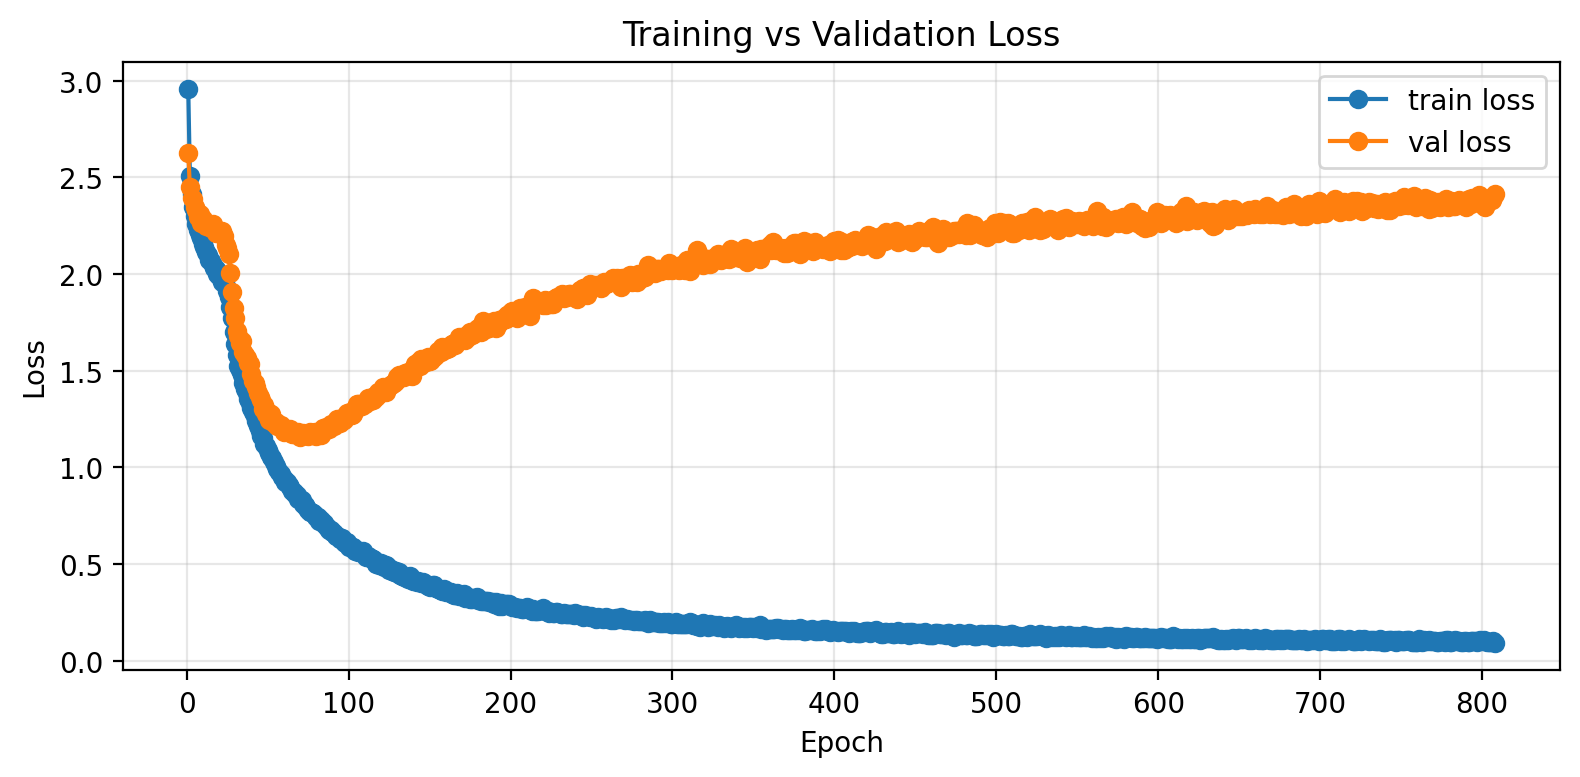

In [3]:
import json, matplotlib.pyplot as plt
from pathlib import Path

cfg_path = Path("/storage/checkpoints/config.json")
if not cfg_path.exists():
    print("No config.json found — train the model first.")
else:
    epoches = json.loads(cfg_path.read_text()).get("epoches", [])
    if not epoches:
        print("No epoch data yet — run the training cell first.")
    else:
        train_losses = [e[0] for e in epoches]
        val_losses   = [e[1] for e in epoches]
        xs = range(1, len(epoches) + 1)

        fig, ax = plt.subplots(figsize=(8, 4))
        ax.plot(xs, train_losses, marker="o", label="train loss")
        ax.plot(xs, val_losses,   marker="o", label="val loss")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.set_title("Training vs Validation Loss")
        ax.legend()
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

## 4. Infill Training

Train a model with Fill-in-the-Middle (FIM) capability. This teaches the model to generate
content that fits between a prefix and suffix context, enabling music in-filling.

In [ ]:
# Infill Training Configuration
INFILL_EPOCHS = 2000
INFILL_BATCH_SIZE = 8
INFILL_LR = 1e-3
INFILL_MAX_FILES = 10000
FIM_RATIO = 0.5  # 50% FIM examples, 50% standard examples

# Build infill model with expanded vocabulary
print("Building infill model with expanded vocabulary (415 tokens)...")
infill_model = build_infill_model().to(DEVICE)
print(f"Infill model parameters: {infill_model.num_params():,}")
print(f"Vocab size: {infill_model.cfg['vocab_size']}")

# Load dataset
paths = load_cached_paths()
if len(paths) < INFILL_MAX_FILES:
    print(f"Downloading up to {INFILL_MAX_FILES} scores...")
    download_dataset(log=print, progress=lambda i, n: None, max_files=INFILL_MAX_FILES)
    paths = load_cached_paths()

print(f"Using {len(paths)} score files for infill training.")

infill_log = []
def infill_log_fn(msg):
    print(msg)
    infill_log.append(msg)
    
# Get config
with open("/storage/checkpoints/config.json") as f:
    cfg = json.load(f)
    
def on_infill_epoch(epoch, train_loss, val_loss):
    print(f"  → epoch {epoch}  train={train_loss:.4f}  val={val_loss:.4f}")
    append_epoch_to_config(cfg, train_loss, val_loss)

stop_flag = [False]  # set stop_flag[0] = True to interrupt training

train_infill(
    model=infill_model,
    data_paths=paths[:INFILL_MAX_FILES],
    epochs=INFILL_EPOCHS,
    batch_size=INFILL_BATCH_SIZE,
    lr=INFILL_LR,
    device=DEVICE,
    log=infill_log_fn,
    on_epoch=on_infill_epoch,
    stop_flag=stop_flag,
    fim_ratio=FIM_RATIO,
)

print(f"\nInfill model saved to: {INFILL_WEIGHTS_FILE}")

Building infill model with expanded vocabulary (415 tokens)...
Infill model parameters: 3,892,224
Vocab size: 415
Fetching file tree from GitHub API...
Found 1462 score files.


Downloading: 100%|██████████| 1462/1462 [00:00<00:00, 81175.42it/s]


Dataset cached: 1462 files in /storage/data/openscore/
Using 1462 score files for infill training.
Parsing scores for infill training...


Parsing scores for infill training...:   0%|          | 0/1462 [00:00<?, ?it/s]/usr/local/lib/python3.11/dist-packages/music21/musicxml/xmlToM21.py:5491: MusicXMLWarning: Could not import wedge: Error in getting DynamicWedges
  warnings.warn(f'Could not import {tag}: {excep}', MusicXMLWarning)
Parsing scores for infill training...:   3%|▎         | 51/1462 [00:23<05:58,  3.94it/s]/usr/local/lib/python3.11/dist-packages/music21/musicxml/xmlToM21.py:4323: MusicXMLWarning: Line <dashes> stop without start
  warnings.warn('Line <' + mxObj.tag + '> stop without start', MusicXMLWarning)
/usr/local/lib/python3.11/dist-packages/music21/musicxml/xmlToM21.py:5491: MusicXMLWarning: Could not import pedal: Error in getting PedalMark
  warnings.warn(f'Could not import {tag}: {excep}', MusicXMLWarning)
Parsing scores for infill training...:   6%|▌         | 89/1462 [01:01<19:14,  1.19it/s]/usr/local/lib/python3.11/dist-packages/music21/musicxml/xmlToM21.py:5491: MusicXMLWarning: Could not import oct

Loaded 1462 scores.
Dataset: 1462 examples (max_len=2048, fim_ratio=0.5)
Split: 1389 train / 73 val examples.


Infill Training Epoch 1: 100%|██████████| 174/174 [00:23<00:00,  7.44it/s]


... (1,608 outputs left out)

  → epoch 805  train=0.0968  val=2.3929
Epoch 805/2000  loss=0.0968  val_loss=2.3929  (infill checkpoint saved)


Infill Training Epoch 806: 100%|██████████| 174/174 [00:24<00:00,  7.06it/s]


  → epoch 806  train=0.0974  val=2.3812
Epoch 806/2000  loss=0.0974  val_loss=2.3812  (infill checkpoint saved)


Infill Training Epoch 807:  76%|███████▌  | 132/174 [00:18<00:05,  7.06it/s]

## 5. Test Infill (Fill Empty Measures)

Test the infill capability by creating a partial XML with empty measures,
then generating content to fill the gaps.

In [2]:
from pathlib import Path

# Create a test partial XML file with empty measures
TEST_XML_PATH = "output/test_partial.xml"
EMPTY_MEASURES = [3, 4, 5]  # measures to leave empty (these will be filled)

Path("output").mkdir(exist_ok=True)
create_test_partial_xml(TEST_XML_PATH, empty_measures=EMPTY_MEASURES)
print(f"Created test file: {TEST_XML_PATH}")
print(f"Empty measures: {EMPTY_MEASURES}")

# Verify gaps are detected
score, gaps = load_partial_xml(TEST_XML_PATH)
print(f"Detected gaps: {gaps}")

Created test file: output/test_partial.xml
Empty measures: [3, 4, 5]
[<music21.stream.Part 0x7f66cc43dd50>]
{1, 2, 3, 4, 5, 6, 7, 8}
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
Detected gaps: [(3, 5)]


In [3]:
# Run infill generation
INFILL_TEMPERATURE = 0.9
INFILL_TOP_K = 50
INFILL_MAX_NEW = 500

# infill_test_log = []
# def infill_test_log_fn(msg):
#     print(msg)
#     infill_test_log.append(msg)

# print("Running infill generation...")
# print("=" * 50)

# result_paths = infill_and_export(
#     xml_path=TEST_XML_PATH,
#     max_new=INFILL_MAX_NEW,
#     temperature=INFILL_TEMPERATURE,
#     top_k=INFILL_TOP_K,
#     log=infill_test_log_fn,
#     device=DEVICE,
# )

# print("=" * 50)
# print(f"\nOutput files:")
# print(f"  MIDI:     {result_paths['midi']}")
# print(f"  MusicXML: {result_paths['xml']}")

# if result_paths["xml"]:
#     print("\n--- Filled Score Preview ---")
#     show_text_score(result_paths["xml"], infill_test_log_fn)

## 7. Test Infill on Real Score

Test infill by taking an existing score from the dataset, removing some measures,
and filling them back in.

In [4]:
import music21 as m21
from pathlib import Path

# Get a score from the dataset
paths = load_cached_paths()
if not paths:
    print("No dataset found. Run Download Dataset first.")
else:
    # Take the first score
    original_path = paths[0]
    print(f"Using score: {original_path}")
    
    # Parse the score
    original_score = m21.converter.parse(original_path)
    
    # Find how many measures it has
    if original_score.parts:
        measures = list(original_score.parts[0].getElementsByClass(m21.stream.Measure))
        n_measures = len(measures)
        print(f"Original score has {n_measures} measures")
        
        if n_measures >= 6:
            # Create a modified score with measures 3-4 emptied
            modified_score = m21.stream.Score()
            
            for part in original_score.parts:
                new_part = m21.stream.Part()
                for measure in part.getElementsByClass(m21.stream.Measure):
                    m_num = measure.number if measure.number is not None else 0
                    new_measure = m21.stream.Measure(number=m_num)
                    
                    if m_num in [3, 4]:
                        rest = m21.note.Rest(quarterLength=4)
                        rest.style.hideObjectOnPrint = True
                        
                        new_measure.elements = []
                        new_measure.insert(0, rest)
                    else:
                        for el in measure:
                            if isinstance(el, (m21.note.Note, m21.note.Rest, m21.chord.Chord, m21.stream.Voice)):
                                new_measure.insert(el.offset, el)

                    new_part.append(new_measure)
                    
#                     # Only copy content for non-gap measures
#                     if m_num not in [3, 4]:
#                         for el in measure:
#                             if isinstance(el, (m21.note.Note, m21.note.Rest, m21.chord.Chord, m21.stream.Voice)):
#                                 new_measure.insert(el.offset, el)
                    
#                     new_part.append(new_measure)
                modified_score.append(new_part)
            
            # Save the modified score
            modified_path = "output/real_partial.xml"
            modified_score.write("musicxml", modified_path)
            # print(f"Created partial score: {modified_path}")
            # print("Emptied measures: 3, 4")
            
            # Verify gaps detected
            gaps = identify_empty_measures(modified_score)
            score.write("musicxml", "output/what_the_heck.xml")
            print(f"Detected gaps: {gaps}")
            
            # Run infill
            print("\nRunning infill on real score...")
            print("=" * 50)
            result_paths = infill_and_export(
                score=modified_score,
                max_new=INFILL_MAX_NEW,
                temperature=INFILL_TEMPERATURE,
                top_k=INFILL_TOP_K,
                log=print,
                device=DEVICE,
            )
            print("=" * 50)
            
            if result_paths["xml"]:
                print("\n--- Filled Score Preview ---")
                show_text_score(result_paths["xml"], print)
        else:
            print(f"Score too short ({n_measures} measures), need at least 6")

Using score: /storage/data/openscore/scores_Abbott,_Jane_Bingham___Just_for_Today_lc6583477.mxl
Original score has 41 measures
[<music21.stream.Part 0x7f66cc1435d0>, <music21.stream.Part 0x7f66cc4b5310>, <music21.stream.Part 0x7f66cc4dce10>]
{1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41}
<music21.note.Rest dotted-half>, True, False
<music21.note.Rest dotted-half>, True, False
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest whole>, True, True
<music21.note.Rest dotted-half>, True, False
<music21.note.Note C>, False, False
<music21.note.Note F>, False, False
<music21.note.Note F>, False, False
<music21.note.Rest dotted-half>, True, False
<music21.note.Rest dotted-half>, True, False
<music21.note.Rest dotted-half>, True, Fa